# Week 4 Day 3 — Feature Engineering, Cross-Validation & Model Comparison
**Dataset:** Adult Census Income

**Goal:** make new features, then compare three models with cross-validation.

The hold-out test set is **not used** today. Everything is done on the training data.

## Step 0: Load the data (same split as Day 1 and Day 2)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_selection import mutual_info_classif, SelectKBest

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

In [2]:
# Upload adult.csv from my computer
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult.csv


In [3]:
df = pd.read_csv("adult.csv")
df = df.replace("?", np.nan)
df["target"] = df["income"].map({"<=50K": 0, ">50K": 1})

X = df.drop(columns=["income", "target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train rows:", len(X_train))

Train rows: 26048


## Task 1: Create new features

I make 8 new features. Each one is made from the person's own row only.

In [4]:
def add_features(data):
    data = data.copy()

    # 1) Age groups
    data["age_group"] = pd.cut(data["age"], bins=[0, 25, 35, 45, 55, 65, 100],
                               labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]).astype(str)

    # 2) Working hours groups
    data["hours_group"] = pd.cut(data["hours.per.week"], bins=[0, 34, 40, 60, 100],
                                 labels=["part-time", "full-time", "overtime", "very-long"]).astype(str)

    # 3) Does the person have any capital gain? (1 = yes, 0 = no)
    data["has_capital_gain"] = (data["capital.gain"] > 0).astype(int)

    # 4) and 5) Log of capital gain and capital loss (makes the huge values smaller)
    data["log_capital_gain"] = np.log1p(data["capital.gain"])
    data["log_capital_loss"] = np.log1p(data["capital.loss"])

    # 6) Bachelors degree or higher? (1 = yes, 0 = no)
    data["higher_education"] = (data["education.num"] >= 13).astype(int)

    # 7) Education multiplied by working hours
    data["edu_x_hours"] = data["education.num"] * data["hours.per.week"]

    # 8) Is the person married? (1 = yes, 0 = no)
    data["is_married"] = data["marital.status"].isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)

    return data

In [5]:
new_features = ["age_group", "hours_group", "has_capital_gain", "log_capital_gain",
                "log_capital_loss", "higher_education", "edu_x_hours", "is_married"]

# Make the new features on the training data and look at them
train_new = add_features(X_train)
train_new[new_features].head()

,age_group,hours_group,has_capital_gain,log_capital_gain,log_capital_loss,higher_education,edu_x_hours,is_married
11219,26-35,full-time,0,0.0,0.0,1,520,0
28304,17-25,overtime,0,0.0,0.0,0,540,1
30810,36-45,full-time,0,0.0,0.0,0,360,1
10958,26-35,full-time,0,0.0,0.0,0,400,0
26814,56-65,full-time,0,0.0,0.0,0,160,0


### How useful is each new feature?

**Check 1: grouped mean.** The percentage of people earning >50K in each group. A big difference between groups means the feature is useful.

In [6]:
train_new["target"] = y_train

for col in ["age_group", "hours_group", "has_capital_gain", "higher_education", "is_married"]:
    print((train_new.groupby(col)["target"].mean() * 100).round(1))
    print()

age_group
17-25     1.7
26-35    18.7
36-45    34.9
46-55    39.7
56-65    31.8
66+      18.9
Name: target, dtype: float64

hours_group
full-time    20.6
overtime     40.8
part-time     7.1
very-long    37.1
Name: target, dtype: float64

has_capital_gain
0    20.6
1    62.0
Name: target, dtype: float64

higher_education
0    16.2
1    48.1
Name: target, dtype: float64

is_married
0     6.4
1    44.8
Name: target, dtype: float64



**Check 2: mutual information.** One score for each feature. A higher score means the feature tells more about the target.

In [7]:
# Mutual information needs numbers, so I change the two group columns to codes
mi_data = train_new[new_features].copy()
mi_data["age_group"] = mi_data["age_group"].astype("category").cat.codes
mi_data["hours_group"] = mi_data["hours_group"].astype("category").cat.codes

# True = the feature has groups or 0/1 values, False = the feature is a real number
is_group = [True, True, True, False, False, True, False, True]

mi_scores = mutual_info_classif(mi_data, y_train, discrete_features=is_group, random_state=42)

### Feature dictionary

In [8]:
feature_dictionary = pd.DataFrame({
    "name": new_features,
    "type": ["category", "category", "0/1 flag", "number", "number", "0/1 flag", "number", "0/1 flag"],
    "rule": [
        "age cut into 6 groups",
        "hours.per.week cut into 4 groups",
        "capital.gain > 0",
        "log(capital.gain + 1)",
        "log(capital.loss + 1)",
        "education.num >= 13",
        "education.num x hours.per.week",
        "marital.status is Married-civ-spouse or Married-AF-spouse",
    ],
    "why it may help": [
        "Income goes up with age and then goes down again",
        "Part-time, full-time and overtime workers earn differently",
        "People with any capital gain are more often high earners",
        "Capital gain has a few huge values, log makes them smaller",
        "Same idea for capital loss",
        "A Bachelors degree or more was a strong signal on Day 1",
        "Educated people who also work long hours should earn the most",
        "Married people earn >50K much more often",
    ],
    "mutual_info": mi_scores.round(3),
})

feature_dictionary = feature_dictionary.sort_values("mutual_info", ascending=False)
feature_dictionary.to_csv("feature_dictionary.csv", index=False)
feature_dictionary

,name,type,rule,why it may help,mutual_info
7,is_married,0/1 flag,marital.status is Married-civ-spouse or Marrie...,Married people earn >50K much more often,0.107
6,edu_x_hours,number,education.num x hours.per.week,Educated people who also work long hours shoul...,0.082
3,log_capital_gain,number,log(capital.gain + 1),"Capital gain has a few huge values, log makes ...",0.081
0,age_group,category,age cut into 6 groups,Income goes up with age and then goes down again,0.062
5,higher_education,0/1 flag,education.num >= 13,A Bachelors degree or more was a strong signal...,0.048
1,hours_group,category,hours.per.week cut into 4 groups,"Part-time, full-time and overtime workers earn...",0.038
4,log_capital_loss,number,log(capital.loss + 1),Same idea for capital loss,0.035
2,has_capital_gain,0/1 flag,capital.gain > 0,People with any capital gain are more often hi...,0.030


**What I see:** `is_married` has the best score. Only 6% of unmarried people earn >50K, but 45% of married people do. `edu_x_hours` and `log_capital_gain` are next.

## Task 2: Pipeline with the new features

The pipeline now has 3 steps: **make new features → preprocessing → model**.

There is no data leakage: each new feature uses only the person's own row, and none of them uses the target.

In [9]:
# Step 1 of the pipeline: make the new features
feature_step = FunctionTransformer(add_features)

# I use the log versions of capital gain and loss, not the raw ones
numeric_features = ["age", "education.num", "hours.per.week",
                    "log_capital_gain", "log_capital_loss", "edu_x_hours",
                    "has_capital_gain", "higher_education", "is_married"]

categorical_features = ["workclass", "marital.status", "occupation", "relationship",
                        "race", "sex", "native.country", "age_group", "hours_group"]

In [10]:
# Step 2 of the pipeline: preprocessing (same idea as Day 2)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# sparse_output=False gives a normal table, which Gradient Boosting needs
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## Task 3: Cross-validation with 3 models

Cross-validation cuts the training data into 5 parts. It trains on 4 parts and tests on 1 part, 5 times. So every model gets 5 scores.

My primary metric is **F1**. I also report ROC AUC.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

In [12]:
# This cell takes about 1 minute
f1_scores = {}
auc_scores = {}
fit_times = {}

for name, model in models.items():
    pipe = Pipeline([
        ("features", feature_step),
        ("preprocess", preprocessor),
        ("model", model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "roc_auc"])

    f1_scores[name] = scores["test_f1"]
    auc_scores[name] = scores["test_roc_auc"]
    fit_times[name] = scores["fit_time"].mean()
    print(name, "done")

Logistic Regression done
Random Forest done
Gradient Boosting done


In [13]:
f1_table = pd.DataFrame(f1_scores)
auc_table = pd.DataFrame(auc_scores)

# The 5 F1 scores of each model
f1_table.round(3)

,Logistic Regression,Random Forest,Gradient Boosting
0,0.675,0.646,0.726
1,0.670,0.657,0.710
2,0.675,0.660,0.713
3,0.672,0.657,0.705
4,0.688,0.678,0.713


In [14]:
# Mean and standard deviation (std = how much the 5 scores move)
cv_summary = pd.DataFrame({
    "F1 mean": f1_table.mean(),
    "F1 std": f1_table.std(),
    "ROC AUC mean": auc_table.mean(),
    "ROC AUC std": auc_table.std(),
})

cv_summary.round(3)

,F1 mean,F1 std,ROC AUC mean,ROC AUC std
Logistic Regression,0.676,0.007,0.914,0.002
Random Forest,0.660,0.011,0.895,0.002
Gradient Boosting,0.713,0.008,0.928,0.002


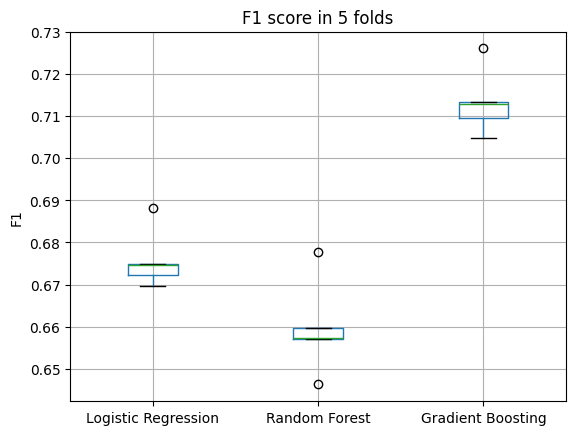

In [15]:
f1_table.boxplot()
plt.title("F1 score in 5 folds")
plt.ylabel("F1")
plt.show()

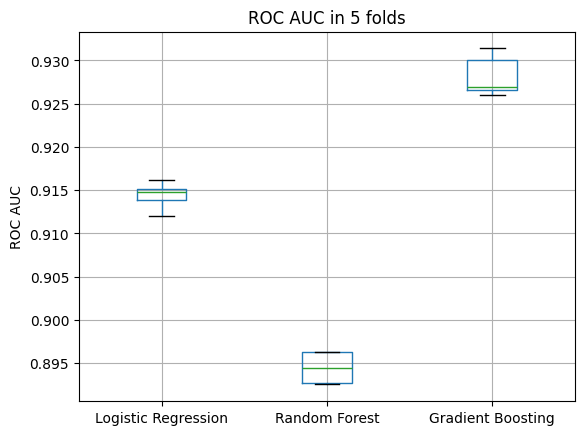

In [16]:
auc_table.boxplot()
plt.title("ROC AUC in 5 folds")
plt.ylabel("ROC AUC")
plt.show()

**Result:** Gradient Boosting is the best model (F1 about 0.71). Logistic Regression is second (about 0.68) and Random Forest is third (about 0.66). The std is very small, so the scores are stable.

### Did the new features help?
I run Logistic Regression and Gradient Boosting again with the old Day 2 features and compare.

In [17]:
# Day 2 features (no new features)
old_numeric = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
old_categorical = ["workclass", "marital.status", "occupation", "relationship", "race", "sex", "native.country"]

old_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, old_numeric),
    ("cat", categorical_pipeline, old_categorical),
])

for name in ["Logistic Regression", "Gradient Boosting"]:
    old_pipe = Pipeline([("preprocess", old_preprocessor), ("model", models[name])])
    old_scores = cross_validate(old_pipe, X_train, y_train, cv=cv, scoring="f1")

    print(name)
    print("  F1 with old features:", round(old_scores["test_score"].mean(), 3))
    print("  F1 with new features:", round(f1_table[name].mean(), 3))

Logistic Regression
  F1 with old features: 0.658
  F1 with new features: 0.676
Gradient Boosting
  F1 with old features: 0.714
  F1 with new features: 0.713


**Result:** the new features help Logistic Regression (F1 goes from about 0.66 to 0.68). They do not change Gradient Boosting. A tree model can make groups like "age 36-45" by itself, so it does not need them.

## Task 4: Statistical test & feature importance

### Is Gradient Boosting really better than Logistic Regression?
A paired t-test compares the 5 fold scores of the top 2 models. If the p-value is under 0.05, the difference is real and not luck.

In [18]:
t_stat, p_value = ttest_rel(f1_table["Gradient Boosting"], f1_table["Logistic Regression"])

difference = f1_table["Gradient Boosting"].mean() - f1_table["Logistic Regression"].mean()

print("Difference in mean F1:", round(difference, 3))
print("p-value:", round(p_value, 4))

Difference in mean F1: 0.037
p-value: 0.001


**Result:** the p-value is far below 0.05, so the difference is real. Gradient Boosting is better in all 5 folds. The gap is about 0.04 in F1, which is big enough to matter in practice.

Note: 5 folds is a small sample, so this test is only a rough check.

### Which new features matter most?
I train Random Forest and Logistic Regression on the full training data and look only at my new features.

In [19]:
rf_pipe = Pipeline([("features", feature_step), ("preprocess", preprocessor), ("model", models["Random Forest"])])
log_pipe = Pipeline([("features", feature_step), ("preprocess", preprocessor), ("model", models["Logistic Regression"])])

rf_pipe.fit(X_train, y_train)
log_pipe.fit(X_train, y_train)

feature_names = rf_pipe.named_steps["preprocess"].get_feature_names_out()
print("Total columns after preprocessing:", len(feature_names))

Total columns after preprocessing: 104


In [20]:
# Words that appear in the names of my new features
new_words = "age_group|hours_group|has_capital_gain|log_capital|higher_education|edu_x_hours|is_married"

# Random Forest: feature importance (higher = used more)
importance_table = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_pipe.named_steps["model"].feature_importances_,
})
importance_table = importance_table[importance_table["feature"].str.contains(new_words)]
importance_table.sort_values("importance", ascending=False).head(8).round(3)

,feature,importance
5,num__edu_x_hours,0.092
3,num__log_capital_gain,0.081
8,num__is_married,0.054
4,num__log_capital_loss,0.032
7,num__higher_education,0.026
6,num__has_capital_gain,0.023
101,cat__hours_group_overtime,0.011
97,cat__age_group_46-55,0.010


In [21]:
# Logistic Regression: coefficients (positive = pushes towards >50K)
coef_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": log_pipe.named_steps["model"].coef_[0],
})
coef_table = coef_table[coef_table["feature"].str.contains(new_words)]
coef_table.sort_values("coefficient", ascending=False).round(2)

,feature,coefficient
3,num__log_capital_gain,8.24
8,num__is_married,1.17
96,cat__age_group_36-45,0.48
97,cat__age_group_46-55,0.45
4,num__log_capital_loss,0.24
101,cat__hours_group_overtime,0.19
95,cat__age_group_26-35,0.11
103,cat__hours_group_very-long,0.04
7,num__higher_education,0.03
98,cat__age_group_56-65,-0.06


**Which new features matter most?**
- **Random Forest:** `edu_x_hours`, `log_capital_gain` and `is_married` are the top three.
- **Logistic Regression:** `log_capital_gain` and `is_married` have the biggest positive numbers. The young (17-25), old (66+) and part-time groups are negative.
- `has_capital_gain` is very negative and `log_capital_gain` is very positive. These two carry almost the same information, so they work as a pair: a small gain does not help much, a big gain helps a lot.

**Does it make sense?** Yes. Capital gain, marriage, education and working hours were also the strong signals on Day 1 and Day 2.

## Task 5: Feature selection

I keep only the 30 best columns (by mutual information) and check if the score or the training time changes. I use my best model, Gradient Boosting.

In [22]:
# Small helper so the mutual information gives the same result every time
def mi_score(X, y):
    return mutual_info_classif(X, y, random_state=42)

select_pipe = Pipeline([
    ("features", feature_step),
    ("preprocess", preprocessor),
    ("select", SelectKBest(mi_score, k=30)),
    ("model", HistGradientBoostingClassifier(random_state=42)),
])

# This cell takes 1 to 3 minutes
select_scores = cross_validate(select_pipe, X_train, y_train, cv=cv, scoring="f1")

In [23]:
print("All features (104 columns)")
print("  F1  :", round(f1_table["Gradient Boosting"].mean(), 3))
print("  Time:", round(fit_times["Gradient Boosting"], 1), "seconds per fold")
print()
print("Best 30 columns")
print("  F1  :", round(select_scores["test_score"].mean(), 3))
print("  Time:", round(select_scores["fit_time"].mean(), 1), "seconds per fold")

All features (104 columns)
  F1  : 0.713
  Time: 1.9 seconds per fold

Best 30 columns
  F1  : 0.694
  Time: 14.1 seconds per fold


**Result:** with only 30 columns the F1 score goes down (about 0.71 to 0.69). Training also gets slower, not faster, because calculating mutual information takes time.

**Decision for tomorrow:** I will keep **all the features**. Removing features lowers the score and saves no time, and 104 columns is not too many for these models.

**Models for tuning:**
- **Gradient Boosting:** the best model (F1 about 0.71).
- **Logistic Regression:** second best, simple and easy to explain.